# Moving averages and market indicators

The bundled DEMO prices are simulated. BUY and SELL are historical crossover labels, not recommendations or trading results.

In [1]:
from IPython.display import Image, display
from indicators import ROOT, load_prices, calculate_indicators, summarize, run

prices = load_prices(ROOT / 'data/demo_prices.csv')
prices.head()

,date,close,volume
0,2025-01-01,102.00,100000
1,2025-01-02,102.60,107919
2,2025-01-03,103.12,115838
3,2025-01-06,103.56,123757
4,2025-01-07,103.93,131676


## 1. Calculate a return by hand
The first return is missing because there is no earlier price in the file.

In [2]:
manual_return = prices.close.iloc[1] / prices.close.iloc[0] - 1
print(f'First observed daily return: {manual_return:.4%}')

First observed daily return: 0.5882%


## 2. Compare trailing windows
A 20-observation average reacts faster than a 50-observation average. The early rows lack enough history; we do not invent values to fill that warm-up period.

In [3]:
result = calculate_indicators(prices, fast=20, slow=50)
display(result[['date', 'close', 'sma_fast', 'sma_slow', 'signal']].iloc[45:55])

,date,close,sma_fast,sma_slow,signal
45,2025-03-05,100.75,107.2875,NaN,NONE
46,2025-03-06,100.12,106.7720,NaN,NONE
47,2025-03-07,99.58,106.2185,NaN,NONE
48,2025-03-10,99.13,105.6355,NaN,NONE
49,2025-03-11,98.76,105.0325,105.9508,NONE
50,2025-03-12,98.49,104.4195,105.8806,NONE
51,2025-03-13,98.30,103.8065,105.7946,NONE
52,2025-03-14,98.18,103.2020,105.6958,NONE
53,2025-03-17,98.14,102.6160,105.5874,NONE
54,2025-03-18,98.14,102.0555,105.4716,NONE


## 3. Inspect events rather than every trend state
A BUY marks the transition from fast <= slow to fast > slow. It is available only after the current close. A later strategy would need a separate execution rule.

In [4]:
display(result.loc[result.signal != 'NONE', ['date', 'close', 'sma_fast', 'sma_slow', 'signal']])
display(summarize(result))

,date,close,sma_fast,sma_slow,signal
88,2025-05-05,106.81,99.9925,99.7544,BUY
137,2025-07-11,105.48,112.0665,112.5166,SELL
175,2025-09-03,109.91,106.5075,106.1916,BUY
224,2025-11-11,114.74,118.2080,118.5408,SELL


{'observations': 260,
 'start': '2025-01-01',
 'end': '2025-12-30',
 'price_return_pct': 13.196078431372538,
 'annualized_volatility_pct': 6.992139335369154,
 'max_drawdown_pct': -12.35890724685097,
 'buy_crossovers': 2,
 'sell_crossovers': 2,
 'latest_trend': 'BELOW',
 'latest_crossover': 'NONE'}

## 4. Interpret risk
Drawdown is the decline from the highest price so far. Volatility measures return variability, not the probability of losing money. The annualization here assumes daily observations and 252 observations per year.

{
  "observations": 260,
  "start": "2025-01-01",
  "end": "2025-12-30",
  "price_return_pct": 13.196078431372538,
  "annualized_volatility_pct": 6.992139335369154,
  "max_drawdown_pct": -12.35890724685097,
  "buy_crossovers": 2,
  "sell_crossovers": 2,
  "latest_trend": "BELOW",
  "latest_crossover": "NONE"
}


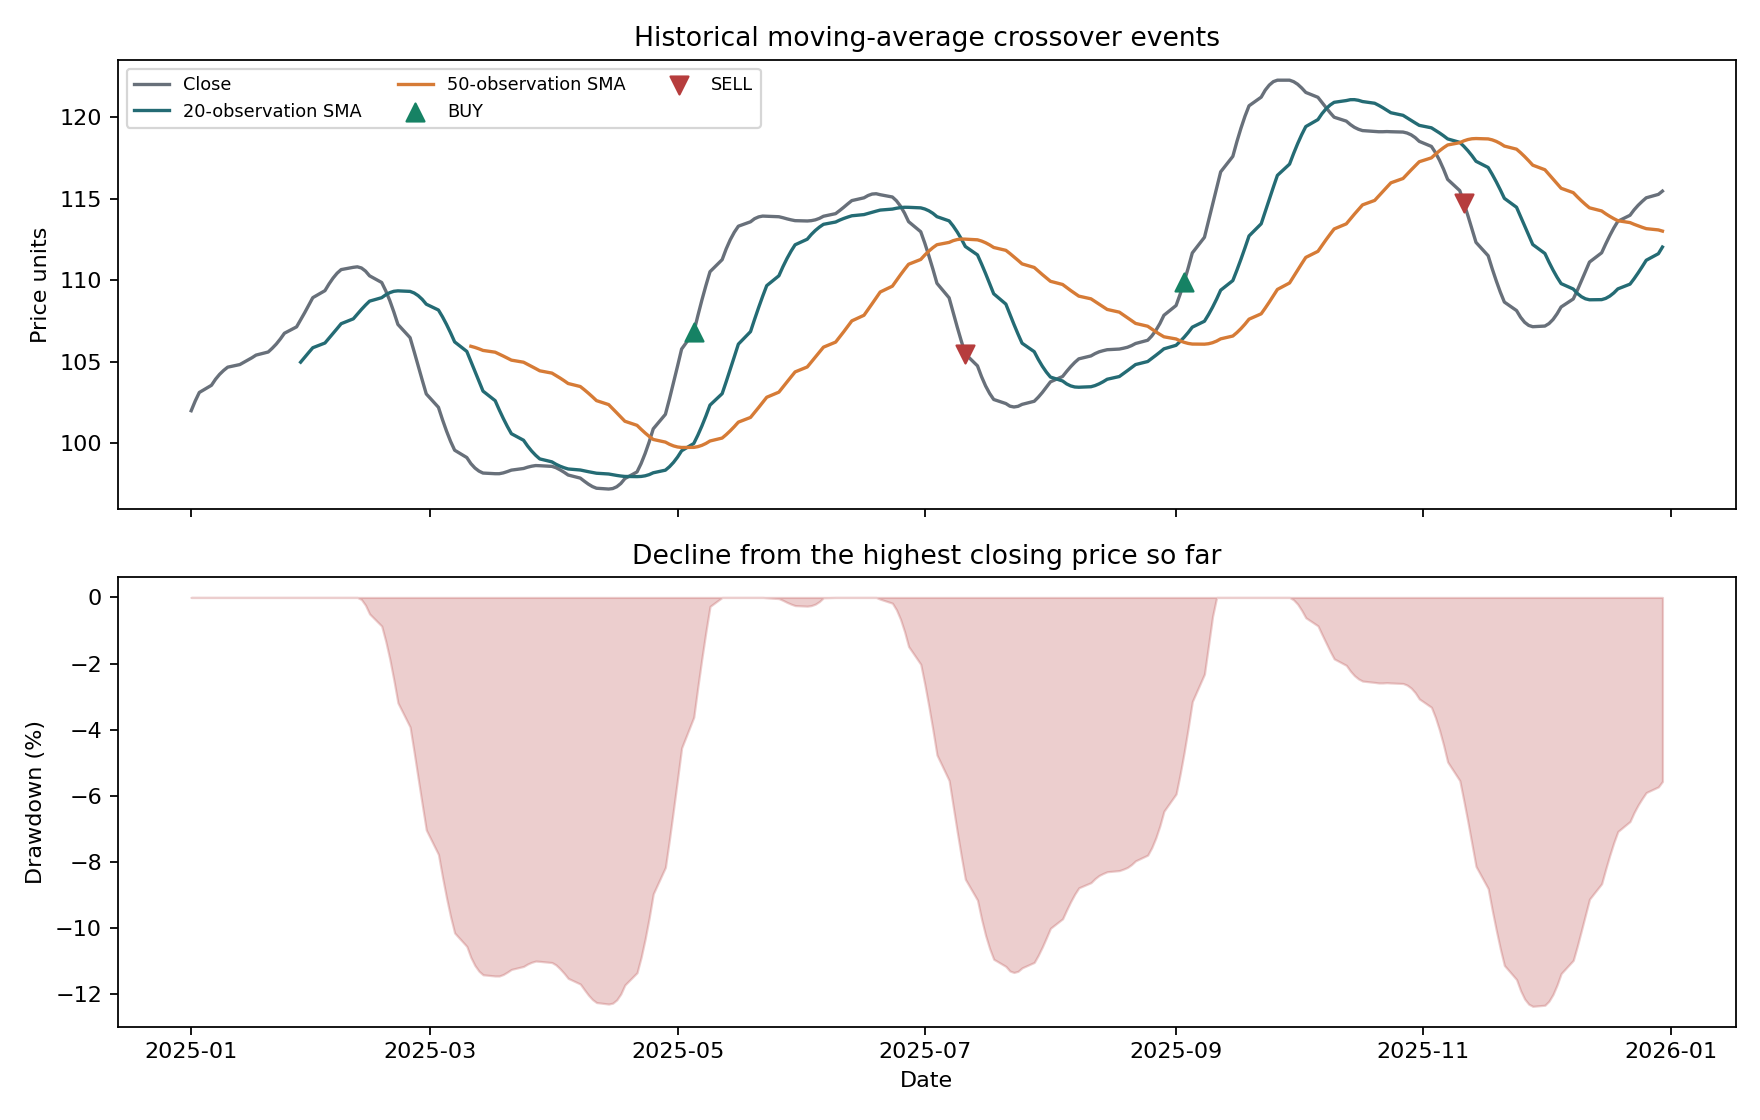

# Market indicator findings

Input: demo_prices.csv. Windows: 20 and 50 observations.

The bundled DEMO dataset is simulated; it is not an actual stock.

- Period: 2025-01-01 to 2025-12-30
- Closing-price return: 13.20%
- Annualized daily volatility (252-observation convention): 6.99%
- Maximum drawdown: -12.36%
- BUY / SELL crossover events: 2 / 2

These are descriptive price statistics, not strategy returns. Signals are known only after the observation's close. No orders, execution prices, fees, dividends, or trading results are modeled.



In [5]:
_ = run()
display(Image(filename=str(ROOT / 'outputs/market_overview.png')))
print((ROOT / 'outputs/report.md').read_text())

## 5. Explore a different window pair
Compare sensitivity without concluding that more signals mean better performance. No strategy return is calculated.

In [6]:
alternative = calculate_indicators(prices, fast=10, slow=30)
print('20/50 events:', result.signal.ne('NONE').sum())
print('10/30 events:', alternative.signal.ne('NONE').sum())

20/50 events: 4
10/30 events: 6


## Practice
Explain why you cannot trade earlier in a day using that day's final close. Add a volume chart. Identify what would be needed to handle a stock split and evaluate a realistic trading strategy.